In [1]:
import pandas as pd
import psycopg2
conn = psycopg2.connect(
    dbname="academy_db",
    host="thomas.proxy.rlwy.net",
    port="51432"
)

In [2]:
ds_transactions = pd.read_sql(
    "SELECT * FROM public.ds_transactions_2;",
    conn
)

ds_cards = pd.read_sql(
    "SELECT * FROM public.ds_cards;",
    conn
)

ds_customers = pd.read_sql(
    "SELECT * FROM public.ds_customers;",
    conn
)

ds_merchants = pd.read_sql(
    "SELECT * FROM public.ds_merchants_2;",
    conn
)

ds_terminals = pd.read_sql(
    "SELECT * FROM public.ds_terminals_2;",
    conn
)

ds_mcc_categories = pd.read_sql(
    "SELECT * FROM public.ds_disputes;",
    conn
)

C:\Users\hp\AppData\Local\Temp\ipykernel_25652\2663308318.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  ds_transactions = pd.read_sql(
C:\Users\hp\AppData\Local\Temp\ipykernel_25652\2663308318.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  ds_cards = pd.read_sql(
C:\Users\hp\AppData\Local\Temp\ipykernel_25652\2663308318.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  ds_customers = pd.read_sql(
C:\Users\hp\AppData\Local\Temp\ipykernel_25652\2663308318.py:16: UserWarning: pandas only supports SQLAlchemy conne

H1. Студенты чаще получают отказы

In [ ]:
# Расчет доли отказов по каждому сегменту клиентов для сравнения уровня отказов.
sql = """
select
    cu.customer_segment as segment,
    count(*) as operations,
    count(t.decline_reason) as declines,
    round(
        100.0 * count(t.decline_reason) / count(*),
        2
    ) as decline_rate
from ds_transactions_2 t
join ds_cards c
    on t.card_id = c.card_id
join ds_customers cu
    on c.customer_id = cu.customer_id
group by cu.customer_segment
order by decline_rate desc;
"""
df = pd.read_sql(sql, conn)
df

C:\Users\hp\AppData\Local\Temp\ipykernel_25652\384994735.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


,segment,operations,declines,decline_rate
0,student,2967,332,11.19
1,premium,8973,531,5.92
2,payroll,16829,984,5.85
3,mass,31551,1831,5.80


In [ ]:
# Расчет медианного чека и доли отказов для поиска возможной связи между ними.
sql = """
select
    cu.customer_segment,
    percentile_cont(0.5) within group(order by t.amount_uzs) as median_ticket,
    round(
        100.0*sum(case when upper(t.txn_status)='DECLINED' then 1 else 0 end)/count(*),
        2
    ) as decline_rate
from ds_transactions_2 t
join ds_cards c on t.card_id=c.card_id
join ds_customers cu on c.customer_id=cu.customer_id
group by cu.customer_segment
order by cu.customer_segment;
"""

df = pd.read_sql(sql, conn)
df

C:\Users\hp\AppData\Local\Temp\ipykernel_25652\3987524348.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


,customer_segment,median_ticket,decline_rate
0,mass,121400.0,5.80
1,payroll,120500.0,5.85
2,premium,118300.0,5.92
3,student,54200.0,11.19


In [ ]:
# Проверка статистической значимости различий между сегментами клиентов.
sql = """
select
    case when cu.customer_segment='student' then 'student'
         else 'others'
    end as segment,
    case when upper(t.txn_status)='DECLINED' then 'declined'
         else 'approved'
    end as status,
    count(*) as n
from ds_transactions_2 t
join ds_cards c on t.card_id=c.card_id
join ds_customers cu on c.customer_id=cu.customer_id
group by 1,2;
"""

tab = pd.read_sql(sql2, conn).pivot(
    index="segment",
    columns="status",
    values="n"
)

from scipy.stats import chi2_contingency

chi2, p, _, _ = chi2_contingency(tab)

print("Chi-square =", round(chi2,2))
print("p-value =", p)

C:\Users\hp\AppData\Local\Temp\ipykernel_25652\2156587589.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  tab = pd.read_sql(sql2, conn).pivot(


Chi-square = 140.39
p-value = 2.1862691404096634e-32


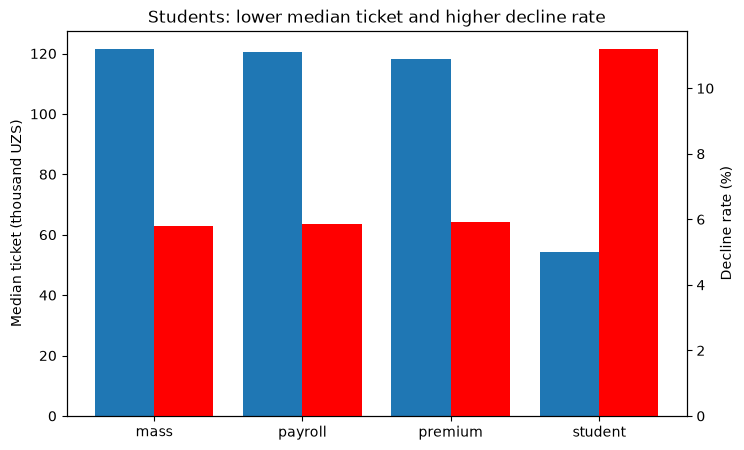

In [ ]:
# Визуализация медианного чека и доли отказов по сегментам.
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(df))

fig, ax1 = plt.subplots(figsize=(8,5))

ax1.bar(x-0.2, df["median_ticket"]/1000, width=0.4, label="Median ticket")
ax1.set_ylabel("Median ticket (thousand UZS)")
ax1.set_xticks(x)
ax1.set_xticklabels(df["customer_segment"])

ax2 = ax1.twinx()
ax2.bar(x+0.2, df["decline_rate"], width=0.4, color="red", label="Decline rate")
ax2.set_ylabel("Decline rate (%)")

plt.title("Students: lower median ticket and higher decline rate")
plt.show()

In [ ]:
# Анализ причин отказов в сегменте студентов.
sql = """
SELECT
    t.decline_reason,
    COUNT(*) AS declines
FROM ds_transactions_2 t
JOIN ds_cards c
    ON t.card_id = c.card_id
JOIN ds_customers cu
    ON c.customer_id = cu.customer_id
WHERE UPPER(t.txn_status)='DECLINED'
  AND cu.customer_segment='student'
GROUP BY t.decline_reason
ORDER BY declines DESC;
"""

df = pd.read_sql(sql, conn)
df

C:\Users\hp\AppData\Local\Temp\ipykernel_25652\1412781746.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


,decline_reason,declines
0,insufficient_funds,174
1,limit,67
2,do_not_honor,57
3,expired_card,34


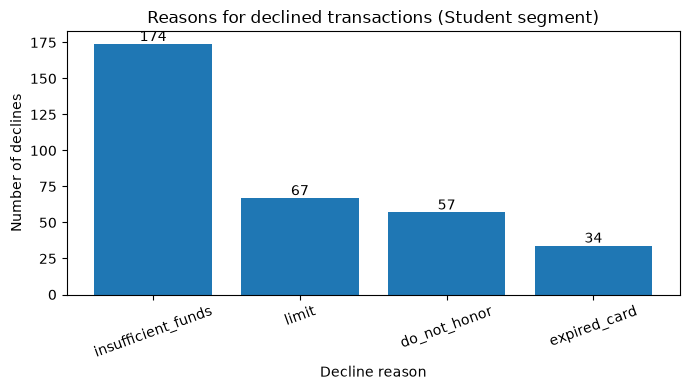

In [ ]:
# Визуализация распределения основных причин отказов у студентов.
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))

plt.bar(df["decline_reason"], df["declines"])

plt.title("Reasons for declined transactions (Student segment)")
plt.xlabel("Decline reason")
plt.ylabel("Number of declines")

plt.xticks(rotation=20)

for i, v in enumerate(df["declines"]):
    plt.text(i, v+2, str(v), ha="center")

plt.tight_layout()
plt.show()

H2.Вероятность возникновения спорной операции зависит от времени проведения операции и способа оплаты. Наибольший риск характерен для ночных интернет-платежей (ecom_cvv).

In [ ]:
# Расчет доли спорных операций по MCC-категориям.
sql = """
SELECT
    mc.category_name,
    COUNT(*) AS transactions,
    SUM(CASE WHEN t.is_disputed THEN 1 ELSE 0 END) AS disputes,
    ROUND(
        100.0 * SUM(CASE WHEN t.is_disputed THEN 1 ELSE 0 END)/COUNT(*),
        2
    ) AS dispute_rate
FROM ds_transactions_2 t
JOIN ds_merchants_2 m
    ON t.merchant_id = m.merchant_id
JOIN ds_mcc_categories mc
    ON m.mcc_code = mc.mcc_code
GROUP BY mc.category_name
ORDER BY dispute_rate DESC;
"""

df = pd.read_sql(sql, conn)
df

C:\Users\hp\AppData\Local\Temp\ipykernel_25652\536794560.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


,category_name,transactions,disputes,dispute_rate
0,Betting,789,132,16.73
1,Online Gaming,220,29,13.18
2,Grocery,3025,5,0.17
3,Fuel,2760,4,0.14
4,Travel,2093,3,0.14
5,ATM Cash,5482,6,0.11
6,Telecom,2705,3,0.11
7,Wholesale,1913,2,0.10
8,Restaurants,3574,3,0.08
9,Mobile Top-up,4431,3,0.07


Наибольшая доля споров наблюдается в категориях Betting и Online Gaming.

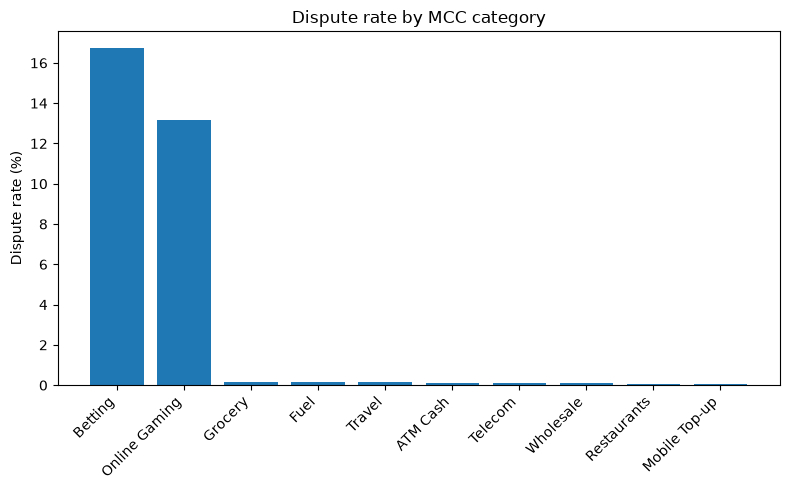

In [ ]:
# Визуализация доли спорных операций по MCC-категориям.
import matplotlib.pyplot as plt

top = df.head(10)

plt.figure(figsize=(8,5))

plt.bar(top["category_name"], top["dispute_rate"])

plt.ylabel("Dispute rate (%)")
plt.title("Dispute rate by MCC category")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
# Анализ влияния времени проведения операции и способа оплаты на вероятность возникновения спора.
sql = """
select
    case
        when extract(hour from t.txn_ts) between 0 and 5
        then 'Night'
        else 'Day'
    end as period,

    t.entry_mode,

    mc.is_high_risk,

    count(*) as transactions,

    sum(case when t.is_disputed then 1 else 0 end) as disputes,

    round(
        100.0 *
        sum(case when t.is_disputed then 1 else 0 end)
        / count(*),
        2
    ) as dispute_rate

from ds_transactions_2 t

join ds_merchants_2 m
    on t.merchant_id=m.merchant_id

join ds_mcc_categories mc
    on m.mcc_code=mc.mcc_code

group by
    period,
    t.entry_mode,
    mc.is_high_risk

order by dispute_rate desc;
"""

df = pd.read_sql(sql, conn)

df

C:\Users\hp\AppData\Local\Temp\ipykernel_25652\3818324915.py:40: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


,period,entry_mode,is_high_risk,transactions,disputes,dispute_rate
0,Night,ecom_cvv,True,347,160,46.11
1,Day,ecom_cvv,True,662,1,0.15
2,Day,chip,False,24522,23,0.09
3,Day,ecom_cvv,False,12949,7,0.05
4,Day,contactless,False,15036,7,0.05
5,Day,chip,True,3650,1,0.03
6,Night,chip,False,1005,0,0.00
7,Night,chip,True,155,0,0.00
8,Night,contactless,False,591,0,0.00
9,Day,fallback_magstripe,False,726,0,0.00


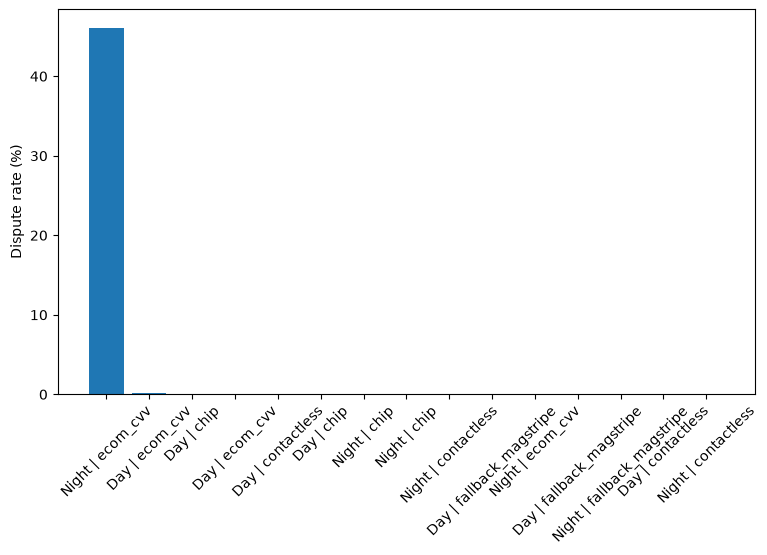

In [ ]:
# Сравнение доли спорных операций по времени проведения и способу оплаты.
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))

plt.bar(
    range(len(df)),
    df["dispute_rate"]
)

plt.xticks(
    range(len(df)),
    df["period"]+" | "+df["entry_mode"],
    rotation=45
)

plt.ylabel("Dispute rate (%)")

plt.show()

 H3. Ночные интернет-платежи значительно рискованнее остальных способов оплаты.

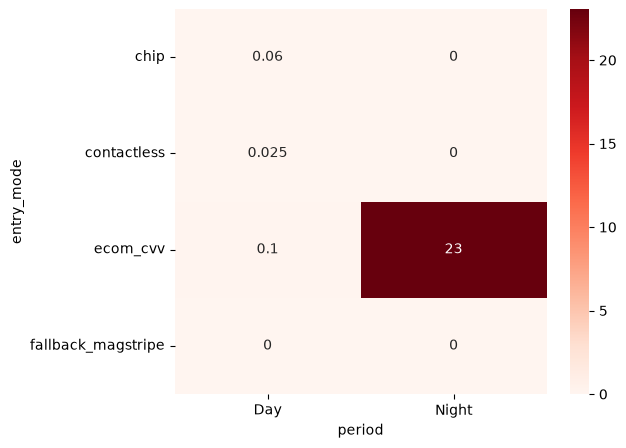

In [ ]:
# Визуализация уровня риска по комбинациям времени проведения операции и способа оплаты.
pivot=df.pivot_table(
    index="entry_mode",
    columns="period",
    values="dispute_rate"
)

import seaborn as sns

plt.figure(figsize=(6,5))

sns.heatmap(
    pivot,
    annot=True,
    cmap="Reds"
)

plt.show()

Наиболее рискованная комбинация — ночные операции с использованием ecom_cvv.

H3. Оборот банка сконцентрирован у небольшой группы мерчантов

In [ ]:
# Рассчитана доля оборота крупнейших мерчантов. Это позволяет оценить, насколько оборот банка зависит от ограниченного числа партнёров.
import pandas as pd

sql = """
WITH merchant_turnover AS (

    SELECT
        merchant_id,
        SUM(amount_uzs) AS turnover
    FROM ds_transactions_2
    WHERE UPPER(txn_status) = 'APPROVED'
    GROUP BY merchant_id

),

ranked AS (

    SELECT
        merchant_id,
        turnover,
        ROW_NUMBER() OVER (ORDER BY turnover DESC) AS rn,
        SUM(turnover) OVER () AS total_turnover
    FROM merchant_turnover

)

SELECT

    ROUND(
        100.0 * SUM(CASE WHEN rn <= 10 THEN turnover ELSE 0 END)
        / MAX(total_turnover),
        2
    ) AS top10_pct,

    ROUND(
        100.0 * SUM(CASE WHEN rn <= 50 THEN turnover ELSE 0 END)
        / MAX(total_turnover),
        2
    ) AS top50_pct,

    ROUND(
        100.0 * SUM(CASE WHEN rn <= 100 THEN turnover ELSE 0 END)
        / MAX(total_turnover),
        2
    ) AS top100_pct

FROM ranked;
"""

top = pd.read_sql(sql, conn)

print(top)

C:\Users\hp\AppData\Local\Temp\ipykernel_25652\3455386334.py:49: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top = pd.read_sql(sql, conn)


   top10_pct  top50_pct  top100_pct
0      25.76      47.24       57.42


Подтверждена высокая концентрация оборота. Топ-10 мерчантов формируют 25,8% оборота, а топ-100 — 57,4%.

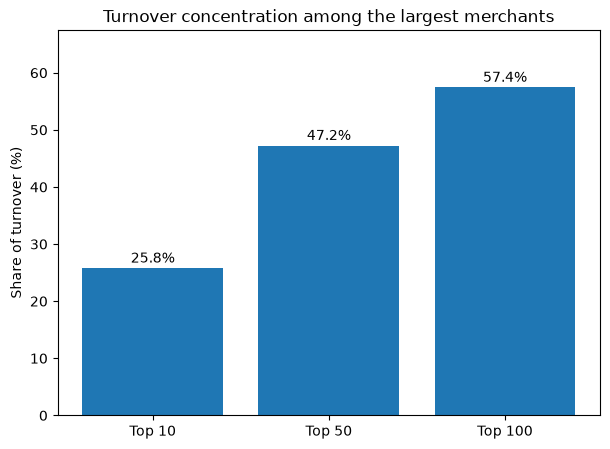

In [ ]:
import matplotlib.pyplot as plt

values = [
    top.loc[0, "top10_pct"],
    top.loc[0, "top50_pct"],
    top.loc[0, "top100_pct"]
]

labels = ["Top 10", "Top 50", "Top 100"]

plt.figure(figsize=(7,5))

bars = plt.bar(labels, values)

for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        h + 1,
        f"{h:.1f}%",
        ha="center"
    )

plt.ylabel("Share of turnover (%)")
plt.title("Turnover concentration among the largest merchants")

plt.ylim(0, max(values) + 10)

plt.show()

In [32]:
sql = """
SELECT
    merchant_id,
    SUM(amount_uzs) AS turnover
FROM ds_transactions_2
GROUP BY merchant_id
"""

df = pd.read_sql(sql, conn)

df.head()

C:\Users\hp\AppData\Local\Temp\ipykernel_25652\1618788219.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


,merchant_id,turnover
0,184,20888400.0
1,87,27694500.0
2,477,20165600.0
3,273,15265500.0
4,550,17292600.0


In [ ]:
# Оценена неравномерность распределения оборота. Для этого рассчитан коэффициент Джини.
import numpy as np

v = np.sort(df["turnover"].values)

n = len(v)

gini = (2*np.sum(np.arange(1,n+1)*v)/(n*np.sum(v))) - (n+1)/n

print("Gini =", round(gini,3))

Gini = 0.563


Получено значение Джини 0,563. Такой уровень свидетельствует о высокой концентрации оборота среди небольшого числа мерчантов.

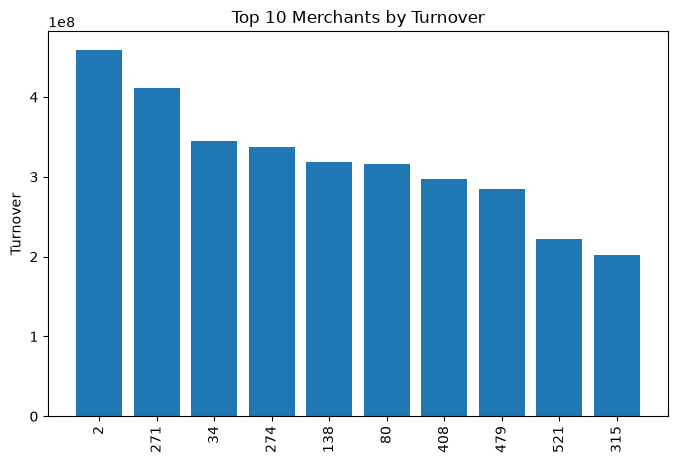

In [ ]:
# Выделены крупнейшие мерчанты по обороту. Несколько партнёров значительно превосходят остальных по объёму операций.
import matplotlib.pyplot as plt

top = df.sort_values("turnover", ascending=False).head(10)

plt.figure(figsize=(8,5))
plt.bar(top["merchant_id"].astype(str), top["turnover"])
plt.xticks(rotation=90)
plt.title("Top 10 Merchants by Turnover")
plt.ylabel("Turnover")
plt.show()

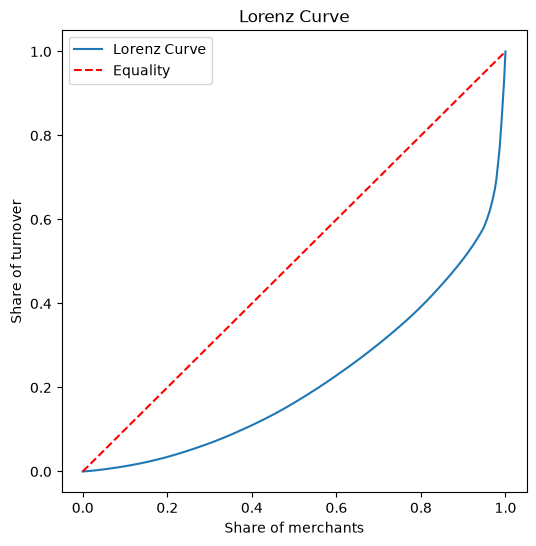

In [35]:
v = np.sort(df["turnover"].values)

cum = np.cumsum(v)/v.sum()

cum = np.insert(cum,0,0)

x = np.linspace(0,1,len(cum))

plt.figure(figsize=(6,6))

plt.plot(x,cum,label="Lorenz Curve")
plt.plot([0,1],[0,1],"r--",label="Equality")

plt.xlabel("Share of merchants")
plt.ylabel("Share of turnover")
plt.title("Lorenz Curve")

plt.legend()

plt.show()

Кривая Лоренца подтверждает концентрацию оборота. Значительное отклонение от линии равенства показывает, что оборот распределён между мерчантами неравномерно.